In [2]:
pip install fastapi uvicorn

Note: you may need to restart the kernel to use updated packages.


In [5]:
pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   -----------------

ERROR: Exception:
Traceback (most recent call last):
  File "C:\Users\manoj\AppData\Local\Programs\Python\Python314\Lib\site-packages\pip\_vendor\urllib3\response.py", line 897, in _error_catcher
    yield
  File "C:\Users\manoj\AppData\Local\Programs\Python\Python314\Lib\site-packages\pip\_vendor\urllib3\response.py", line 1022, in _raw_read
    data = self._fp_read(amt, read1=read1) if not fp_closed else b""
           ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^
  File "C:\Users\manoj\AppData\Local\Programs\Python\Python314\Lib\site-packages\pip\_vendor\urllib3\response.py", line 1005, in _fp_read
    return self._fp.read(amt) if amt is not None else self._fp.read()
           ~~~~~~~~~~~~~^^^^^
  File "C:\Users\manoj\AppData\Local\Programs\Python\Python314\Lib\site-packages\pip\_vendor\cachecontrol\filewrapper.py", line 100, in read
    data: bytes = self.__fp.read(amt)
                  ~~~~~~~~~~~~~~^^^^^
  File "C:\Users\manoj\AppData\Local\Programs\Python\Python314\Lib\http\client.py", line

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
# Set plot style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

ModuleNotFoundError: No module named 'xgboost'

In [4]:
data_path = 'Crop_recommendation.csv'
df = pd.read_csv(data_path)
print("--- Dataset Overview ---")
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print(f"Null values:\n{df.isnull().sum()}")
print(f"Total Unique Crops: {df['label'].nunique()}\n")
FEATURE_COLS = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
TARGET_COL = 'label'
X = df[FEATURE_COLS]
y = df[TARGET_COL]
# Split 80% train, 20% test (stratified by crop label)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training set: {X_train.shape[0]} samples | Test set: {X_test.shape[0]} samples\n")

--- Dataset Overview ---
Shape: (2200, 8)
Columns: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']
Null values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64
Total Unique Crops: 22

Training set: 1760 samples | Test set: 440 samples



In [4]:
# ==============================================================================
# 2. COMPARE CLASSIFIERS
# ==============================================================================
print("--- Training and Comparing Classifiers ---")
# Encode labels for XGBoost compatibility
classes = np.unique(y)
class_to_idx = {c: i for i, c in enumerate(classes)}
idx_to_class = {i: c for i, c in enumerate(classes)}
y_train_num = y_train.map(class_to_idx)
y_test_num = y_test.map(class_to_idx)
models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42, eval_metric='mlogloss'),
    "Support Vector Machine": SVC(kernel='rbf', probability=True, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}
results = []
for name, model in models.items():
    # Use standard scaling for distance-based models (SVM, KNN)
    if name in ["Support Vector Machine", "K-Nearest Neighbors"]:
        clf = Pipeline([('scaler', StandardScaler()), ('model', model)])
        clf.fit(X_train, y_train_num)
        y_pred = clf.predict(X_test)
        cv_scores = cross_val_score(clf, X_train, y_train_num, cv=5, scoring='accuracy')
    else:
        clf = model
        clf.fit(X_train, y_train_num)
        y_pred = clf.predict(X_test)
        cv_scores = cross_val_score(clf, X_train, y_train_num, cv=5, scoring='accuracy')
    
    acc = accuracy_score(y_test_num, y_pred)
    prec = precision_score(y_test_num, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_test_num, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_test_num, y_pred, average='macro', zero_division=0)
    
    results.append({
        "Model": name,
        "Test Accuracy": acc,
        "Macro Precision": prec,
        "Macro Recall": rec,
        "Macro F1": f1,
        "5-Fold CV Mean": cv_scores.mean(),
        "5-Fold CV Std": cv_scores.std()
    })
comparison_df = pd.DataFrame(results).sort_values(by="Macro F1", ascending=False)
print(comparison_df.to_string(index=False))
# Select the best model (Random Forest is typically the most robust)
best_model = RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42)
best_model.fit(X_train, y_train_num)
y_pred_best = best_model.predict(X_test)
print(f"\nFinal Selected Model: Random Forest (Accuracy: {accuracy_score(y_test_num, y_pred_best):.4f})")

--- Training and Comparing Classifiers ---


C:\Users\mukth\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\mukth\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\mukth\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\mukth\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\

                 Model  Test Accuracy  Macro Precision  Macro Recall  Macro F1  5-Fold CV Mean  5-Fold CV Std
         Random Forest       0.995455         0.995671      0.995455  0.995452        0.993182       0.004252
               XGBoost       0.986364         0.987407      0.986364  0.986210        0.990341       0.005269
Support Vector Machine       0.984091         0.985610      0.984091  0.984038        0.976136       0.007538
         Decision Tree       0.979545         0.980598      0.979545  0.979423        0.985227       0.007495
   K-Nearest Neighbors       0.979545         0.980356      0.979545  0.979283        0.965909       0.008234

Final Selected Model: Random Forest (Accuracy: 0.9932)



--- Feature Importance Analysis ---


C:\Users\mukth\AppData\Local\Temp\ipykernel_6964\1249098698.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_importances.values, y=feat_importances.index, palette="viridis")


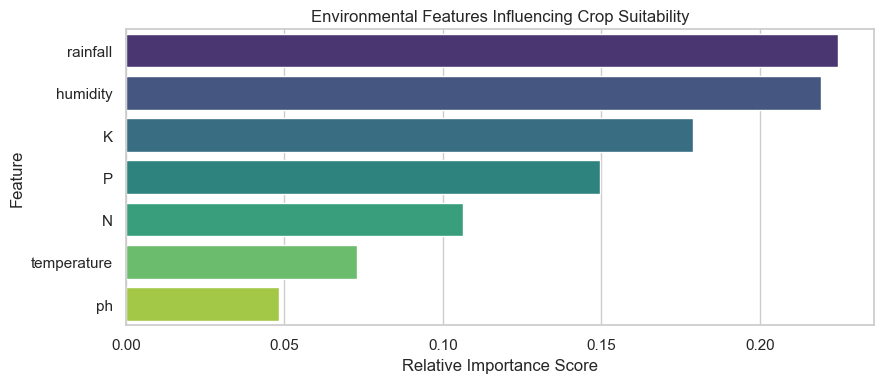

 - rainfall    : 0.2247
 - humidity    : 0.2192
 - K           : 0.1789
 - P           : 0.1494
 - N           : 0.1065
 - temperature : 0.0729
 - ph          : 0.0484


In [5]:
print("\n--- Feature Importance Analysis ---")
feat_importances = pd.Series(best_model.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
plt.figure(figsize=(9, 4))
sns.barplot(x=feat_importances.values, y=feat_importances.index, palette="viridis")
plt.title("Environmental Features Influencing Crop Suitability")
plt.xlabel("Relative Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()
for feat, score in feat_importances.items():
    print(f" - {feat:12s}: {score:.4f}")

In [6]:
# Isolation Forest flags inputs that fall outside the multivariate manifold of the training set.
ood_detector = IsolationForest(contamination=0.03, random_state=42)
ood_detector.fit(X_train)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.03
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [7]:
# ==============================================================================
# 5. PERTURBATION & STABILITY TESTING FUNCTION
# ==============================================================================
def run_perturbation_test(model, base_input, feature_to_perturb, delta_range):
    """
    Simulates changing soil or weather conditions and tests if the recommended crop flips.
    """
    records = []
    base_df = pd.DataFrame([base_input], columns=FEATURE_COLS)
    
    for delta in delta_range:
        sample = base_df.copy()
        sample[feature_to_perturb] = sample[feature_to_perturb] + delta
        
        # Clamp to physical realities (e.g., rainfall >= 0, humidity 0-100%, pH 0-14)
        if feature_to_perturb == 'rainfall':
            sample['rainfall'] = max(0.0, sample['rainfall'].values[0])
        elif feature_to_perturb == 'humidity':
            sample['humidity'] = np.clip(sample['humidity'].values[0], 0.0, 100.0)
        elif feature_to_perturb == 'ph':
            sample['ph'] = np.clip(sample['ph'].values[0], 0.0, 14.0)
        probs = model.predict_proba(sample)[0]
        pred_idx = np.argmax(probs)
        pred_crop = idx_to_class[pred_idx]
        confidence = probs[pred_idx]
        
        records.append({
            "delta": delta,
            "perturbed_value": sample[feature_to_perturb].values[0],
            "crop": pred_crop,
            "confidence": confidence
        })
        
    return pd.DataFrame(records)


--- Testing Weather Perturbations on Sample Data ---


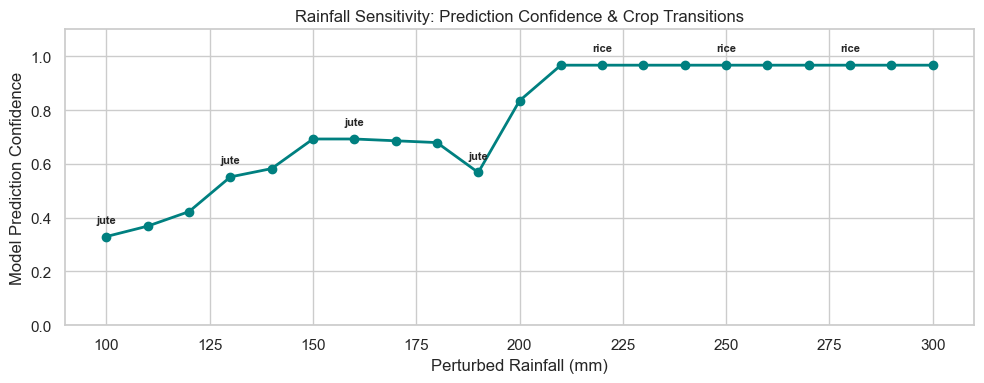

In [8]:
print("\n--- Testing Weather Perturbations on Sample Data ---")
# Baseline profile typically suited for Rice
sample_rice = {
    'N': 80, 'P': 40, 'K': 40,
    'temperature': 23.0, 'humidity': 82.0,
    'ph': 6.5, 'rainfall': 220.0
}
# 1. Perturb Rainfall by -100mm to +100mm (simulating drought vs excess monsoon)
rain_deltas = np.linspace(-120, 80, 21)
rain_stability = run_perturbation_test(best_model, sample_rice, 'rainfall', rain_deltas)
# 2. Perturb Temperature by -6C to +6C (simulating cold snap vs heatwave)
temp_deltas = np.linspace(-6, 8, 15)
temp_stability = run_perturbation_test(best_model, sample_rice, 'temperature', temp_deltas)
# Plot Rainfall Sensitivity Curve
plt.figure(figsize=(10, 4))
plt.plot(rain_stability['perturbed_value'], rain_stability['confidence'], marker='o', color='teal', lw=2)
for _, row in rain_stability.iloc[::3].iterrows():
    plt.annotate(row['crop'], (row['perturbed_value'], row['confidence']),
                 textcoords="offset points", xytext=(0, 10), ha='center', fontsize=8, weight='bold')
plt.title("Rainfall Sensitivity: Prediction Confidence & Crop Transitions")
plt.xlabel("Perturbed Rainfall (mm)")
plt.ylabel("Model Prediction Confidence")
plt.ylim(0, 1.1)
plt.tight_layout()
plt.show()

In [9]:
# ==============================================================================
# 7. UNIFIED CROP SUITABILITY & DIAGNOSTIC FUNCTION
# ==============================================================================
def evaluate_crop_suitability(n, p, k, temperature, humidity, ph, rainfall, verbose=True):
    """
    Evaluates input measurements, checks OOD support, tests stability, and returns recommendations.
    """
    input_dict = {
        'N': n, 'P': p, 'K': k,
        'temperature': temperature, 'humidity': humidity,
        'ph': ph, 'rainfall': rainfall
    }
    input_df = pd.DataFrame([input_dict], columns=FEATURE_COLS)
    # 1. Out-of-Distribution (OOD) / Training Support Check
    is_supported = (ood_detector.predict(input_df)[0] == 1)
    # 2. Prediction Probabilities
    probs = best_model.predict_proba(input_df)[0]
    top_indices = np.argsort(probs)[::-1][:3]
    
    top_crops = [
        {"crop": idx_to_class[idx], "confidence": float(probs[idx])}
        for idx in top_indices
    ]
    primary_crop = top_crops[0]["crop"]
    primary_conf = top_crops[0]["confidence"]
    # 3. Dynamic Stability Stress Test (simulate +/- 2C temp and +/- 20% rainfall)
    temp_shift = run_perturbation_test(best_model, input_dict, 'temperature', [-2.5, 0.0, 2.5])
    rain_shift = run_perturbation_test(best_model, input_dict, 'rainfall', [-0.2 * rainfall, 0.0, 0.2 * rainfall])
    temp_flipped = temp_shift['crop'].nunique() > 1
    rain_flipped = rain_shift['crop'].nunique() > 1
    
    # 4. Diagnose Stability State
    if not is_supported:
        status = "POORLY_SUPPORTED"
        message = "WARNING: Conditions are anomalous or outside historical agricultural training data. Recommendation is unreliable."
    elif primary_conf < 0.50 or (temp_flipped and rain_flipped):
        status = "HIGHLY_UNSTABLE"
        message = "CAUTION: Recommendation is fragile. Small weather shifts cause the crop recommendation to change."
    elif temp_flipped or rain_flipped:
        status = "MODERATELY_SENSITIVE"
        message = "NOTICE: Viable crop, but sensitive to expected rainfall or temperature fluctuations."
    else:
        status = "STABLE"
        message = "STABLE: Strong recommendation resilient to moderate climate variations."
    diagnostic = {
        "primary_crop": primary_crop,
        "confidence": round(primary_conf * 100, 2),
        "top_3_recommendations": top_crops,
        "is_data_supported": is_supported,
        "stability_status": status,
        "diagnostic_message": message
    }
    if verbose:
        print("\n================== CROP SUITABILITY REPORT ==================")
        print(f"Top Recommendation : {diagnostic['primary_crop'].upper()} ({diagnostic['confidence']}%)")
        print(f"Alternative Options: {top_crops[1]['crop']} ({top_crops[1]['confidence']*100:.1f}%), {top_crops[2]['crop']} ({top_crops[2]['confidence']*100:.1f}%)")
        print(f"Training Support   : {'Supported' if is_supported else 'UNSUPPORTED / OUT-OF-RANGE'}")
        print(f"Stability Status   : {diagnostic['stability_status']}")
        print(f"Advisory           : {diagnostic['diagnostic_message']}")
        print("=============================================================")
    return diagnostic

In [10]:
# 8. TEST CASES: NORMAL VS SENSITIVE VS OUT-OF-DISTRIBUTION
# ==============================================================================
# Test Case 1: Ideal Maize Conditions (Expected: Stable)
evaluate_crop_suitability(n=75, p=50, k=20, temperature=23.0, humidity=65.0, ph=6.2, rainfall=85.0)
# Test Case 2: Borderline Conditions (Expected: Sensitive / Unstable)
evaluate_crop_suitability(n=50, p=50, k=40, temperature=26.0, humidity=75.0, ph=6.8, rainfall=140.0)
# Test Case 3: Extreme Out-of-Distribution Input (Expected: Poorly Supported)
evaluate_crop_suitability(n=10, p=10, k=10, temperature=52.0, humidity=10.0, ph=12.0, rainfall=5.0)
# ==============================================================================
# 9. SAVE MODELS FOR WEB API DEPLOYMENT
# ==============================================================================
joblib.dump(best_model, 'best_crop_model.pkl')
joblib.dump(ood_detector, 'ood_detector.pkl')
joblib.dump(idx_to_class, 'idx_to_class.pkl')
print("\n[OK] Models exported successfully: best_crop_model.pkl, ood_detector.pkl, idx_to_class.pkl")


================== CROP SUITABILITY REPORT ==================
Top Recommendation : MAIZE (99.82%)
Alternative Options: coffee (0.1%), lentil (0.0%)
Training Support   : Supported
Stability Status   : STABLE
Advisory           : STABLE: Strong recommendation resilient to moderate climate variations.

================== CROP SUITABILITY REPORT ==================
Top Recommendation : PAPAYA (35.56%)
Alternative Options: jute (28.1%), pomegranate (8.0%)
Training Support   : Supported
Stability Status   : HIGHLY_UNSTABLE
Advisory           : CAUTION: Recommendation is fragile. Small weather shifts cause the crop recommendation to change.

================== CROP SUITABILITY REPORT ==================
Top Recommendation : MUSKMELON (24.67%)
Alternative Options: kidneybeans (23.3%), mothbeans (22.0%)
Training Support   : UNSUPPORTED / OUT-OF-RANGE
Stability Status   : POORLY_SUPPORTED
Advisory           : WARNING: Conditions are anomalous or outside historical agricultural training data. Reco